# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [1]:
import hashlib
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 600                       # used by the bootstrap later; recorded in decisions.md when it matters
rng = np.random.default_rng(SEED)

RAW = Path("data/raw")
FIG = Path("fig")
FIG.mkdir(exist_ok=True)

# The files this notebook reads, with the SHA-256 from data/README.md.
# 2021 is not read (decisions.md, 2026-11-06).
FILES = {
    2022: ("NSDUH-2022-DS0001-bndl-data-tsv_v2.zip", "cde54c4af548de3cacebff00127fda4ffa645fb9cd4803dbd0ae9ed3df1c799f"),
    2023: ("nsduh-2023-ds0001-bndl-data-tsv_v2.zip", "f2ed2fb234ebe04b6548e827fd90138830bb6bc8411e215a526d0ef3ddcd9324"),
    2024: ("NSDUH-2024-DS0001-bndl-data-tsv_v1.zip", "a26f3009991e848c9a6b594e5d57906621a75459c7ba51d10b409ed2f8432a8f"),
}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

for year, (name, expected) in FILES.items():
    got = sha256(RAW / name)
    assert got == expected, f"{name}: SHA-256 {got} does not match data/README.md"
print(f"{len(FILES)} files match the SHA-256 in data/README.md")


3 files match the SHA-256 in data/README.md


## Question

One sentence, then the quantity with units and a time window. Save the layer diagram, data to model to prediction to decision, as `fig/layers.png`.

![Layer diagram](fig/layers.png)


**Question.** Among adults in mental-health treatment, can five intake answers pick out who is still having serious thoughts of suicide well enough that sorting new FirstHarbor clients by risk costs less than starting every client at the same level of monitoring?

**Quantity.** For an adult who received mental-health treatment in the past 12 months, the probability that they seriously thought about killing themselves in the past 12 months. Scored on the 2023 survey, and checked on 2024, as the expected loss per 100 new clients, in units of one unneeded week of close monitoring.

**Decision.** As FirstHarbor's founder, I decide whether to build intake screening and where to set its threshold. Loss per 100 new clients: L = r · FN + FP. The costlier mistake is the miss (FN): an at-risk client started on standard monitoring costs r weeks of close monitoring, with r between 2 and 500 (`REFERENCES.md`).

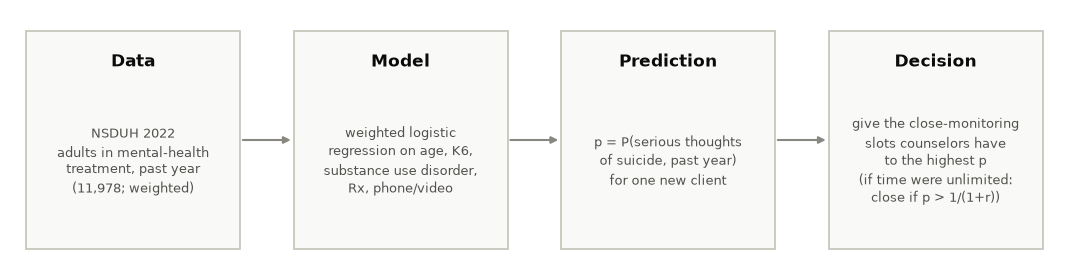

In [2]:
# Layer diagram: data -> model -> prediction -> decision.
layers = [
    ("Data", "NSDUH 2022\nadults in mental-health\ntreatment, past year\n(11,978; weighted)"),
    ("Model", "weighted logistic\nregression on age, K6,\nsubstance use disorder,\nRx, phone/video"),
    ("Prediction", "p = P(serious thoughts\nof suicide, past year)\nfor one new client"),
    ("Decision", "give the close-monitoring\nslots counselors have\nto the highest p\n(if time were unlimited:\nclose if p > 1/(1+r))"),
]
fig, ax = plt.subplots(figsize=(11, 2.9))
ax.set_xlim(0, 4); ax.set_ylim(0, 1); ax.axis("off")
for i, (head, body) in enumerate(layers):
    ax.add_patch(plt.Rectangle((i + 0.06, 0.08), 0.8, 0.84, facecolor="#f9f9f7", edgecolor="#c3c2b7", lw=1.2))
    ax.text(i + 0.46, 0.80, head, ha="center", va="center", fontsize=12, color="#0b0b0b", weight="bold")
    ax.text(i + 0.46, 0.42, body, ha="center", va="center", fontsize=9.5, color="#52514e", linespacing=1.4)
    if i < 3:
        ax.annotate("", xy=(i + 1.06, 0.5), xytext=(i + 0.86, 0.5),
                    arrowprops=dict(arrowstyle="-|>", color="#898781", lw=1.5))
fig.tight_layout(); fig.savefig(FIG / "layers.png", dpi=150); plt.show()


## Data

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

If the terms do not let you republish the files, there is no release: run the download command in `data/README.md` instead. The upload commands are in `data/README.md` too. Read the files from `data/`. Show one plot of the raw data and one table of summary statistics before any model. Save the plot under `fig/`.


,adults,in treatment,share in treatment (wtd),"at risk, n","at risk, rate (wtd)",role
2022,47100,11978,21.5%,2014,13.4%,train
2023,45133,11851,23.1%,1938,12.7%,test
2024,47299,12444,23.0%,1814,11.9%,check (new wording)


n by year,2022,2023,2024
age,,,
18-25,3914,3689,3753
26-34,2610,2591,2806
35-49,3423,3539,3733
50-64,1187,1157,1237
65+,844,875,915


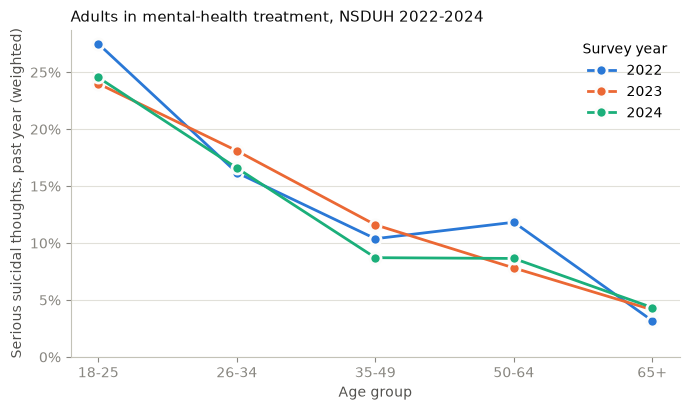

In [3]:
# "In treatment" is MHTRTPY in 2022-2023 and MHTRTPY2 in 2024; SAMHSA says 2024 is not comparable.
TRT = {2022: "MHTRTPY", 2023: "MHTRTPY", 2024: "MHTRTPY2"}
COLS = ["QUESTID2", "CATAG6", "IRSUICTHNK", "ANALWT2_C", "VESTR_C", "VEREP",
        "KSSLR6MON", "UD5ILALANY", "IRMHTRXMED", "IRMHTPHVID"]   # the five intake predictors (with CATAG6)
AGE = {2: "18-25", 3: "26-34", 4: "35-49", 5: "50-64", 6: "65+"}

def load(year):
    """Read one year's TSV straight from its zip, without unzipping."""
    with zipfile.ZipFile(RAW / FILES[year][0]) as zf:
        (name,) = zf.namelist()          # each zip holds exactly one file
        with zf.open(name) as fh:
            d = pd.read_csv(fh, sep="\t", usecols=COLS + [TRT[year]])
    return d.rename(columns={TRT[year]: "in_trt"}).assign(year=year)

everyone = pd.concat([load(y) for y in FILES], ignore_index=True)
adults = everyone[everyone.CATAG6 >= 2]
df = adults[adults.in_trt == 1].copy()          # the population: adults in MH treatment, past year
df["at_risk"] = df.IRSUICTHNK.astype(int)       # serious suicidal thoughts, past year (imputation-revised)
df["age"] = pd.Categorical(df.CATAG6.map(AGE), categories=list(AGE.values()), ordered=True)
assert df.at_risk.isin([0, 1]).all()
assert df.KSSLR6MON.between(0, 24).all()
assert df[["UD5ILALANY", "IRMHTRXMED", "IRMHTPHVID"]].isin([0, 1]).all().all()

def wmean(x, w):
    return (x * w).sum() / w.sum()

summary = pd.DataFrame({
    "adults": adults.groupby("year").size(),
    "in treatment": df.groupby("year").size(),
    "share in treatment (wtd)": adults.groupby("year").apply(lambda g: wmean(g.in_trt == 1, g.ANALWT2_C)),
    "at risk, n": df.groupby("year").at_risk.sum(),
    "at risk, rate (wtd)": df.groupby("year").apply(lambda g: wmean(g.at_risk, g.ANALWT2_C)),
    "role": pd.Series({2022: "train", 2023: "test", 2024: "check (new wording)"}),
})
pct = ["share in treatment (wtd)", "at risk, rate (wtd)"]
display(summary.assign(**{k: summary[k].map("{:.1%}".format) for k in pct}))

by_age = (df.groupby(["year", "age"], observed=True)
            .apply(lambda g: pd.Series({"n": len(g), "rate": wmean(g.at_risk, g.ANALWT2_C)}))
            .reset_index())
display(by_age.pivot(index="age", columns="year", values="n").astype(int).rename_axis(columns="n by year"))

# Raw-data plot: weighted rate of serious suicidal thoughts by age group, one line per year.
COLORS = {2022: "#2a78d6", 2023: "#eb6834", 2024: "#1baf7a"}   # categorical slots 1-3, fixed order
fig, ax = plt.subplots(figsize=(7, 4.2))
for year, g in by_age.groupby("year"):
    ax.plot(g.age.astype(str), g.rate, color=COLORS[year], lw=2, marker="o", ms=8,
            markeredgecolor="#fcfcfb", markeredgewidth=2, label=str(year))
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Age group", color="#52514e")
ax.set_ylabel("Serious suicidal thoughts, past year (weighted)", color="#52514e")
ax.set_title("Adults in mental-health treatment, NSDUH 2022-2024", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="y", color="#e1e0d9", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, title="Survey year", loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "raw_rate_by_age.png", dpi=150)
plt.show()


**Reading.** About 12,000 adults in treatment per year, about 1,800 to 2,000 of them at risk. The weighted rate falls every year: 13.4%, 12.7%, 11.9%. Age is the clearest pattern in the raw data: about a quarter of 18–25-year-olds in treatment report serious thoughts of suicide, against 3–4% at 65 and over.

How the measurement differs from what the decision needs (`PROPOSAL.md`): FirstHarbor's clients are invited by a counselor, not drawn at random; the answers cover the past year, not the moment of intake; and they are given to a survey, not a clinical app. All three are bias, not noise. "In treatment" is also defined differently in 2024.

## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.


In [4]:
# Split by survey year (decisions.md, 2026-11-06). No random draw.
train = df[df.year == 2022]
test = df[df.year == 2023]      # same treatment definition as train
check = df[df.year == 2024]     # new treatment wording from June 2024: a shift check, never used to fit or choose
for name, d in [("train 2022", train), ("test 2023", test), ("check 2024", check)]:
    print(f"{name}: {len(d):>6,} adults in treatment, {d.at_risk.sum():>5,} at risk, "
          f"weighted rate {wmean(d.at_risk, d.ANALWT2_C):.1%}")


train 2022: 11,978 adults in treatment, 2,014 at risk, weighted rate 13.4%
test 2023: 11,851 adults in treatment, 1,938 at risk, weighted rate 12.7%
check 2024: 12,444 adults in treatment, 1,814 at risk, weighted rate 11.9%


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.


In [5]:
# Loss per 100 new clients, in units of one unneeded week of close monitoring:
#   L = 100 * (r * P(at risk and put on standard) + P(not at risk and put on close)),
# with probabilities weighted by ANALWT2_C so they describe the population, not the sample.
R_GRID = np.array([2, 5, 10, 14, 29, 50, 100, 150, 300, 500])   # r from 2 to 500 (decisions.md, 2026-10-26)

def loss_per_100(at_risk, close, w, r):
    """at_risk, close: 0/1 arrays; w: weights. Returns L for each r."""
    w = np.asarray(w) / np.sum(w)
    fn = np.sum(w * (at_risk == 1) * (close == 0))     # at risk, put on standard monitoring
    fp = np.sum(w * (at_risk == 0) * (close == 1))     # not at risk, put on close monitoring
    return 100 * (np.asarray(r) * fn + fp)

# Baseline: everyone starts at the same level. Which level is cheaper depends on r and on the
# at-risk rate p: all-standard costs 100*r*p, all-close costs 100*(1-p). The choice is made with
# p from the training year only, then scored on the held-out years.
p_train = wmean(train.at_risk, train.ANALWT2_C)
r_switch = (1 - p_train) / p_train
print(f"p (2022, weighted) = {p_train:.3f}; everyone-close is cheaper than everyone-standard when r > {r_switch:.1f}")

def baseline_loss(d, r):
    out = []
    for r_ in np.atleast_1d(r):
        close = np.full(len(d), int(r_ > r_switch))        # one level for everyone, chosen on 2022
        out.append(loss_per_100(d.at_risk.to_numpy(), close, d.ANALWT2_C, r_))
    return np.array(out)

base = pd.DataFrame({
    "r": R_GRID,
    "level (chosen on 2022)": np.where(R_GRID > r_switch, "all close", "all standard"),
    "L all standard, 2023": loss_per_100(test.at_risk.to_numpy(), np.zeros(len(test)), test.ANALWT2_C, R_GRID),
    "L all close, 2023": loss_per_100(test.at_risk.to_numpy(), np.ones(len(test)), test.ANALWT2_C, R_GRID),
    "baseline L, 2023": baseline_loss(test, R_GRID),
    "baseline L, 2024": baseline_loss(check, R_GRID),
}).set_index("r")
display(base.round(1))


p (2022, weighted) = 0.134; everyone-close is cheaper than everyone-standard when r > 6.4


,level (chosen on 2022),"L all standard, 2023","L all close, 2023","baseline L, 2023","baseline L, 2024"
r,,,,,
2,all standard,25.4,87.3,25.4,23.7
5,all standard,63.6,87.3,63.6,59.3
10,all close,127.1,87.3,87.3,88.1
14,all close,178.0,87.3,87.3,88.1
29,all close,368.7,87.3,87.3,88.1
50,all close,635.6,87.3,87.3,88.1
100,all close,1271.3,87.3,87.3,88.1
150,all close,1906.9,87.3,87.3,88.1
300,all close,3813.9,87.3,87.3,88.1


**Reading.** With 13.4% at risk in 2022, starting everyone on close monitoring is cheaper than starting everyone on standard once r > 6.4. So across almost the whole range of r, the baseline is everyone on close monitoring, at 87.3 per 100 new clients on 2023. A screen can win only by finding clients who are safe to start on standard monitoring.

## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.


### The model

Logistic regression, fit on 2022 with the survey weights `ANALWT2_C`:

$$\log\frac{p_i}{1-p_i} = \beta_0 + \beta_{\text{age}[i]} + \beta_1\,\text{K6}_i + \beta_2\,\text{SUD}_i + \beta_3\,\text{Rx}_i + \beta_4\,\text{Tele}_i$$

- $p_i$: the probability that adult $i$ in treatment had serious thoughts of suicide in the past year (`IRSUICTHNK`).
- $\beta_{\text{age}}$: one shift per age group, relative to 18–25 (`CATAG6`).
- $\beta_1$: the change in log-odds per point of K6 psychological distress in the past month, 0 to 24 (`KSSLR6MON`).
- $\beta_2$: a drug or alcohol use disorder in the past year (`UD5ILALANY`).
- $\beta_3$: took prescription medication for mental health in the past year (`IRMHTRXMED`).
- $\beta_4$: received mental-health treatment by phone or video in the past year (`IRMHTPHVID`).

The action: close monitoring when $\hat p_i > 1/(1+r)$, the threshold at which $r \cdot \hat p_i$, the expected cost of a miss, exceeds $1 - \hat p_i$, the expected cost of an unneeded week.

The assumption trusted least: K6 enters as a straight line on the log-odds scale. Standard errors below treat the weighted sample as simple random, so they are too narrow. A design-based interval (clusters within strata) comes later.


In [6]:
import statsmodels.api as sm

def design(d):
    X = pd.get_dummies(d.age, prefix="age", drop_first=True, dtype=float)   # 18-25 is the reference
    X["k6"] = d.KSSLR6MON.astype(float)
    X["sud"] = d.UD5ILALANY.astype(float)
    X["rx"] = d.IRMHTRXMED.astype(float)
    X["tele"] = d.IRMHTPHVID.astype(float)
    return sm.add_constant(X)

w_train = train.ANALWT2_C / train.ANALWT2_C.mean()
model = sm.GLM(train.at_risk, design(train), family=sm.families.Binomial(), var_weights=w_train).fit()
coefs = pd.DataFrame({"coef": model.params, "odds ratio": np.exp(model.params),
                      "naive SE": model.bse})
display(coefs.round(3))

def model_loss(d, r):
    p_hat = model.predict(design(d)).to_numpy()
    return np.array([loss_per_100(d.at_risk.to_numpy(), (p_hat > 1 / (1 + r_)).astype(int), d.ANALWT2_C, r_)
                     for r_ in np.atleast_1d(r)])

def share_close(d, r):
    p_hat = model.predict(design(d)).to_numpy()
    return np.array([wmean(p_hat > 1 / (1 + r_), d.ANALWT2_C) for r_ in np.atleast_1d(r)])

scores = pd.DataFrame({
    "r": R_GRID,
    "threshold": 1 / (1 + R_GRID),
    "baseline 2023": baseline_loss(test, R_GRID),
    "model 2023": model_loss(test, R_GRID),
    "share on close, 2023": share_close(test, R_GRID),
    "baseline 2024": baseline_loss(check, R_GRID),
    "model 2024": model_loss(check, R_GRID),
}).set_index("r")
scores["model - baseline, 2023"] = scores["model 2023"] - scores["baseline 2023"]
scores["model - baseline, 2024"] = scores["model 2024"] - scores["baseline 2024"]
display(scores.round(3))

# Calibration in the large: weighted mean prediction against the weighted observed rate.
for name, d in [("train 2022", train), ("test 2023", test), ("check 2024", check)]:
    p_hat = model.predict(design(d))
    print(f"{name}: predicted {wmean(p_hat, d.ANALWT2_C):.1%}, observed {wmean(d.at_risk, d.ANALWT2_C):.1%}")


,coef,odds ratio,naive SE
const,-3.732,0.024,0.111
age_26-34,-0.573,0.564,0.086
age_35-49,-0.844,0.430,0.085
age_50-64,-0.515,0.597,0.088
age_65+,-1.416,0.243,0.148
k6,0.186,1.204,0.006
sud,0.360,1.434,0.062
rx,0.402,1.495,0.075
tele,0.258,1.295,0.065


,threshold,baseline 2023,model 2023,"share on close, 2023",baseline 2024,model 2024,"model - baseline, 2023","model - baseline, 2024"
r,,,,,,,,
2,0.333,25.426,21.264,0.104,23.735,21.922,-4.162,-1.813
5,0.167,63.565,39.276,0.244,59.339,37.848,-24.289,-21.491
10,0.091,87.287,54.538,0.399,88.132,53.577,-32.749,-34.555
14,0.067,87.287,60.745,0.492,88.132,64.563,-26.542,-23.569
29,0.033,87.287,71.740,0.707,88.132,74.515,-15.547,-13.617
50,0.020,87.287,79.742,0.859,88.132,89.867,-7.545,1.734
100,0.010,87.287,84.876,0.976,88.132,88.889,-2.411,0.757
150,0.007,87.287,86.732,0.994,88.132,87.427,-0.555,-0.706
300,0.003,87.287,87.287,1.000,88.132,88.132,0.000,0.000


train 2022: predicted 13.4%, observed 13.4%
test 2023: predicted 12.6%, observed 12.7%
check 2024: predicted 12.9%, observed 11.9%


**Reading.** On 2023 the model costs less than the baseline for r from 2 to 150, and ties from r = 300, where its threshold is so low that it puts everyone on close monitoring. Overall calibration: predicted 12.6% against 12.7% observed on 2023, and 12.9% against 11.9% on 2024.

### Uncertainty of the savings

NSDUH samples clusters, not people: each year has 50 variance strata (`VESTR_C`) with 2 clusters each (`VEREP`). People in one cluster resemble each other, so the 12,000 adults per year carry less information than 12,000 independent draws.

Rao-Wu bootstrap, 500 replicates, seed 600. In each replicate, for every stratum, keep one of its two clusters at random and double its weights. Do this independently for 2022, 2023, and 2024. Refit the model on the 2022 replicate, choose the baseline level from the 2022 replicate's rate, and score both on the 2023 and 2024 replicates. The interval is the 2.5th to 97.5th percentile of the savings (model loss minus baseline loss). A jackknife was rejected: the loss jumps at the threshold 1/(1+r), and the jackknife is unreliable for statistics that are not smooth.


In [7]:
B = 500
boot_rng = np.random.default_rng(SEED)

def half_sample(d, rng):
    """Rao-Wu with 2 clusters per stratum: keep one cluster per stratum, double its weights."""
    psus = d.groupby("VESTR_C").VEREP.unique()
    keep = {s: rng.choice(v) for s, v in psus.items()}
    out = d[d.VEREP.to_numpy() == d.VESTR_C.map(keep).to_numpy()].copy()
    out["ANALWT2_C"] = out.ANALWT2_C * 2
    return out

def savings(m, p_tr, d, r_grid):
    """Model loss minus baseline loss on d, at each r, for a model m and a training rate p_tr."""
    p_hat = m.predict(design(d)).to_numpy()
    y, w = d.at_risk.to_numpy(), d.ANALWT2_C
    out = []
    for r_ in r_grid:
        model_L = loss_per_100(y, (p_hat > 1 / (1 + r_)).astype(int), w, r_)
        base_L = loss_per_100(y, np.full(len(d), int(r_ > (1 - p_tr) / p_tr)), w, r_)
        out.append(model_L - base_L)
    return np.array(out)

reps = {"2023": [], "2024": []}
for b in range(B):
    tr, te, ch = half_sample(train, boot_rng), half_sample(test, boot_rng), half_sample(check, boot_rng)
    w = tr.ANALWT2_C / tr.ANALWT2_C.mean()
    m_b = sm.GLM(tr.at_risk, design(tr), family=sm.families.Binomial(), var_weights=w).fit()
    p_b = wmean(tr.at_risk, tr.ANALWT2_C)
    reps["2023"].append(savings(m_b, p_b, te, R_GRID))
    reps["2024"].append(savings(m_b, p_b, ch, R_GRID))

unc = pd.DataFrame({"r": R_GRID}).set_index("r")
for yr, d in [("2023", test), ("2024", check)]:
    arr = np.array(reps[yr])
    unc[f"model - baseline {yr}"] = savings(model, p_train, d, R_GRID)
    unc[f"low {yr}"] = np.percentile(arr, 2.5, axis=0)
    unc[f"high {yr}"] = np.percentile(arr, 97.5, axis=0)
    unc[f"P(model better) {yr}"] = (arr < 0).mean(axis=0)
display(unc.round(2))


,model - baseline 2023,low 2023,high 2023,P(model better) 2023,model - baseline 2024,low 2024,high 2024,P(model better) 2024
r,,,,,,,,
2,-4.16,-5.37,-2.93,1.00,-1.81,-3.87,-0.52,1.00
5,-24.29,-28.23,-20.03,1.00,-21.49,-25.43,-16.77,1.00
10,-32.75,-37.72,-27.77,1.00,-34.55,-38.19,-28.63,1.00
14,-26.54,-31.78,-19.57,1.00,-23.57,-30.41,-19.09,1.00
29,-15.55,-21.53,-5.21,1.00,-13.62,-17.13,-2.95,1.00
50,-7.54,-12.58,3.48,0.91,1.73,-8.36,10.79,0.44
100,-2.41,-5.97,6.32,0.76,0.76,-2.49,20.68,0.27
150,-0.56,-3.40,4.72,0.62,-0.71,-1.57,24.07,0.37
300,0.00,-0.69,0.00,0.06,0.00,-0.74,0.00,0.05


**Reading.** The savings are below zero, with intervals that exclude zero, for r from 2 to 29 in both 2023 and 2024. From r = 50 up, the intervals include zero: no evidence that the screen helps. Where the method wins: r ≤ 29. Where it ties: r ≥ 50.

## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


In [8]:
# Simulate outcomes from the fitted model on the real 2022 predictors, with the fitted coefficients
# as the known truth. Refit each simulated data set. If the fit is sound, the refits center on the truth.
S = 200
sim_rng = np.random.default_rng(SEED + 1)
X_train = design(train)
p_true = model.predict(X_train).to_numpy()
fits, sim_age = [], []
for s in range(S):
    y_sim = (sim_rng.random(len(p_true)) < p_true).astype(int)
    fits.append(sm.GLM(y_sim, X_train, family=sm.families.Binomial(), var_weights=w_train).fit().params)
    sim_age.append(pd.Series(y_sim * train.ANALWT2_C.to_numpy()).groupby(train.age.to_numpy(), observed=True).sum()
                   / train.groupby("age", observed=True).ANALWT2_C.sum().to_numpy())
fits = pd.DataFrame(fits)
recovery = pd.DataFrame({"true (fitted on 2022)": model.params, "mean of refits": fits.mean(),
                         "sd of refits": fits.std()})
recovery["bias / sd"] = (recovery["mean of refits"] - recovery["true (fitted on 2022)"]) / recovery["sd of refits"]
print(f"Parameter recovery, {S} simulated data sets")
display(recovery.round(3))

# Simulated data against the real data: the at-risk rate by age group.
sim_age = pd.DataFrame(sim_age)
real_age = train.groupby("age", observed=True).apply(lambda g: wmean(g.at_risk, g.ANALWT2_C))
print("Rate of serious suicidal thoughts by age group, 2022: real vs simulated from the model")
display(pd.DataFrame({"real": real_age.to_numpy(), "simulated, 2.5%": sim_age.quantile(0.025).to_numpy(),
                      "simulated, 97.5%": sim_age.quantile(0.975).to_numpy()},
                     index=real_age.index).round(3))


Parameter recovery, 200 simulated data sets


,true (fitted on 2022),mean of refits,sd of refits,bias / sd
const,-3.732,-3.774,0.186,-0.228
age_26-34,-0.573,-0.572,0.138,0.005
age_35-49,-0.844,-0.839,0.131,0.038
age_50-64,-0.515,-0.499,0.167,0.095
age_65+,-1.416,-1.430,0.323,-0.045
k6,0.186,0.189,0.011,0.306
sud,0.360,0.358,0.110,-0.018
rx,0.402,0.398,0.138,-0.028
tele,0.258,0.253,0.113,-0.044


Rate of serious suicidal thoughts by age group, 2022: real vs simulated from the model


,real,"simulated, 2.5%","simulated, 97.5%"
age,,,
18-25,0.275,0.253,0.298
26-34,0.162,0.141,0.185
35-49,0.104,0.090,0.119
50-64,0.118,0.094,0.142
65+,0.032,0.018,0.053


**Reading.** The fit recovers the known coefficients: every refit average is within 0.3 standard deviations of the truth. Data simulated from the model look like the real data: the real rate in every age group lies inside the simulated 95% range, including the 2022 rise at 50–64, which is consistent with chance.

## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


Calibration by decile of predicted risk, 2023


,n,predicted,observed,se,residual,residual / se
bin,,,,,,
1,1193.0,0.015,0.013,0.005,-0.002,-0.371
2,1185.0,0.027,0.020,0.007,-0.008,-1.084
3,1182.0,0.040,0.039,0.010,-0.001,-0.141
4,1196.0,0.056,0.068,0.013,0.012,0.935
5,1178.0,0.078,0.094,0.015,0.017,1.111
6,1181.0,0.109,0.120,0.017,0.011,0.646
7,1188.0,0.155,0.167,0.019,0.012,0.622
8,1179.0,0.222,0.219,0.021,-0.002,-0.112
9,1193.0,0.333,0.345,0.025,0.011,0.450


Calibration by decile of predicted risk, 2024


,n,predicted,observed,se,residual,residual / se
bin,,,,,,
1,1313.0,0.015,0.019,0.006,0.004,0.706
2,1238.0,0.028,0.016,0.006,-0.013,-2.027
3,1204.0,0.041,0.030,0.009,-0.011,-1.202
4,1223.0,0.057,0.085,0.015,0.028,1.934
5,1264.0,0.078,0.052,0.011,-0.026,-2.466
6,1242.0,0.108,0.103,0.015,-0.006,-0.358
7,1227.0,0.150,0.159,0.019,0.009,0.464
8,1258.0,0.218,0.221,0.022,0.004,0.163
9,1237.0,0.330,0.288,0.023,-0.042,-1.867


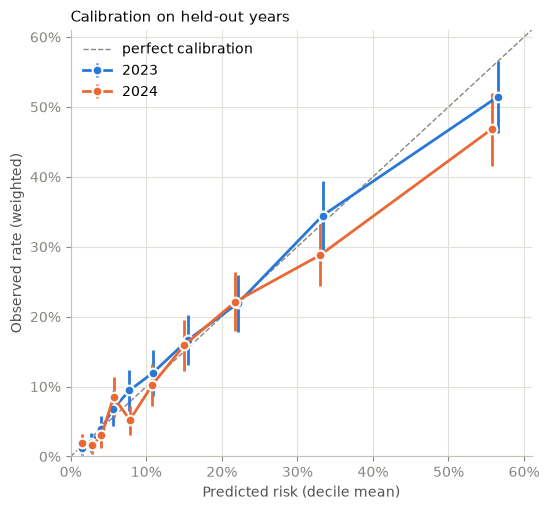

Observed vs predicted by K6 band, train 2022


,n,predicted,observed,se,residual,residual / se
bin,,,,,,
0-4,3465.0,0.028,0.024,0.005,-0.004,-0.868
5-8,3188.0,0.074,0.065,0.008,-0.008,-1.060
9-12,2568.0,0.160,0.176,0.014,0.016,1.164
13-16,1595.0,0.299,0.339,0.022,0.040,1.848
17-20,810.0,0.457,0.423,0.034,-0.033,-0.980
21-24,352.0,0.671,0.597,0.055,-0.074,-1.340


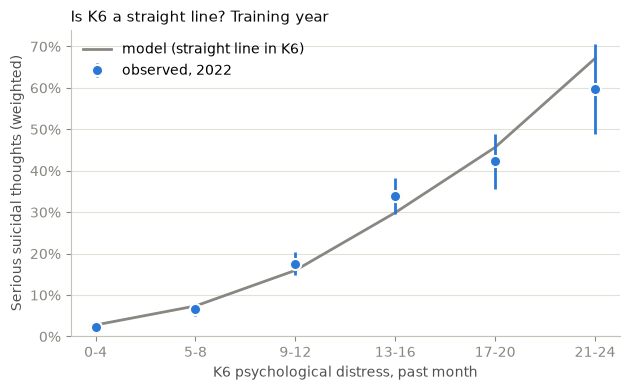

In [9]:
# 1. Calibration and residuals: bin the predictions into deciles, then compare the weighted observed
#    rate with the weighted mean prediction in each bin. Residual = observed - predicted.
#    The interval uses Kish's effective sample size, which allows for unequal weights but not for
#    clustering, so it is still somewhat too narrow.
def binned(d, by, bins):
    t = pd.DataFrame({"p_hat": model.predict(design(d)).to_numpy(), "y": d.at_risk.to_numpy(),
                      "w": d.ANALWT2_C.to_numpy(), "by": by})
    t["bin"] = bins(t.by)
    def agg(g):
        n_eff = g.w.sum() ** 2 / (g.w ** 2).sum()
        obs = wmean(g.y, g.w)
        return pd.Series({"n": len(g), "predicted": wmean(g.p_hat, g.w), "observed": obs,
                          "se": np.sqrt(obs * (1 - obs) / n_eff)})
    out = t.groupby("bin", observed=True).apply(agg)
    out["residual"] = out.observed - out.predicted
    out["residual / se"] = out.residual / out.se
    return out

deciles = lambda s: pd.qcut(s, 10, labels=range(1, 11))
cal = {name: binned(d, model.predict(design(d)).to_numpy(), deciles)
       for name, d in [("2023", test), ("2024", check)]}
for name, t in cal.items():
    print(f"Calibration by decile of predicted risk, {name}")
    display(t.round(3))

COLORS_CAL = {"2023": "#2a78d6", "2024": "#eb6834"}   # categorical slots 1-2
fig, ax = plt.subplots(figsize=(5.6, 5.2))
top = max(t[["predicted", "observed"]].to_numpy().max() for t in cal.values()) * 1.08
ax.plot([0, top], [0, top], color="#898781", lw=1, ls="--", label="perfect calibration")
for name, t in cal.items():
    ax.errorbar(t.predicted, t.observed, yerr=1.96 * t.se, color=COLORS_CAL[name], lw=2, marker="o", ms=7,
                markeredgecolor="#fcfcfb", markeredgewidth=1.5, capsize=0, label=name)
ax.set_xlim(0, top); ax.set_ylim(0, top)
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Predicted risk (decile mean)", color="#52514e")
ax.set_ylabel("Observed rate (weighted)", color="#52514e")
ax.set_title("Calibration on held-out years", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
for side in ("left", "bottom"): ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "calibration.png", dpi=150); plt.show()

# 2. The assumption trusted least: K6 enters as a straight line on the log-odds scale.
#    On the training year, compare the observed rate in each K6 band with the mean prediction.
k6_bands = lambda s: pd.cut(s, [-1, 4, 8, 12, 16, 20, 24], labels=["0-4", "5-8", "9-12", "13-16", "17-20", "21-24"])
k6 = binned(train, train.KSSLR6MON.to_numpy(), k6_bands)
print("Observed vs predicted by K6 band, train 2022")
display(k6.round(3))

fig, ax = plt.subplots(figsize=(6.4, 4))
x = np.arange(len(k6))
ax.plot(x, k6.predicted, color="#898781", lw=2, label="model (straight line in K6)")
ax.errorbar(x, k6.observed, yerr=1.96 * k6.se, color="#2a78d6", lw=0, elinewidth=2, marker="o", ms=8,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5, label="observed, 2022")
ax.set_xticks(x, k6.index.astype(str))
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, None)
ax.set_xlabel("K6 psychological distress, past month", color="#52514e")
ax.set_ylabel("Serious suicidal thoughts (weighted)", color="#52514e")
ax.set_title("Is K6 a straight line? Training year", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="y", color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
for side in ("left", "bottom"): ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "k6_check.png", dpi=150); plt.show()


**Reading.** Noise or bias? On 2023, nine of the ten residuals are within about 1.1 standard errors of zero: noise. The top decile is over-predicted (56.5% predicted, 51.4% observed, 1.9 standard errors). On 2024 the over-prediction at the top grows (55.7% against 46.8%, 3.3 standard errors): bias, growing with distance from the training data, both in time and in the definition of treatment. Overall calibration is off by 0.1 point on 2023 and 1.0 point on 2024.

This bias does not change any action: for r ≥ 5 every threshold is 17% or less, and clients predicted at 50% get close monitoring either way.

The assumption trusted least, K6 as a straight line on the log-odds scale, holds within about two standard errors in every band. The top band, K6 21–24, is the miss (fit 67%, observed 60%), the same over-prediction.

## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


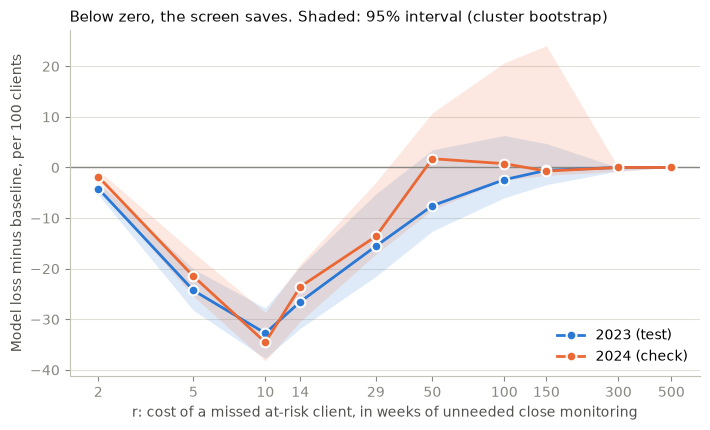

Share of new clients put on close monitoring (2023), by r


,threshold 1/(1+r),share on close
r,,
2,0.333,0.104
5,0.167,0.244
10,0.091,0.399
14,0.067,0.492
29,0.033,0.707
50,0.020,0.859
100,0.010,0.976
150,0.007,0.994
300,0.003,1.000


Loss per 100 clients, 2023: what a better model could still save


,baseline (no screen),model,perfect screen,model's savings,share of the possible savings,left for a better model
r,,,,,,
2,25.43,21.26,0.0,4.16,0.16,21.26
5,63.56,39.28,0.0,24.29,0.38,39.28
10,87.29,54.54,0.0,32.75,0.38,54.54
14,87.29,60.75,0.0,26.54,0.30,60.75
29,87.29,71.74,0.0,15.55,0.18,71.74
50,87.29,79.74,0.0,7.54,0.09,79.74
100,87.29,84.88,0.0,2.41,0.03,84.88
150,87.29,86.73,0.0,0.56,0.01,86.73
300,87.29,87.29,0.0,0.00,0.00,87.29


Loss per 100 clients on 2023, by training size


,model on all of 2022,model on half of 2022 (mean of 100),cost of halving the data
r,,,
2,21.26,21.32,0.06
5,39.28,39.34,0.07
10,54.54,54.48,-0.06
14,60.75,61.15,0.41
29,71.74,73.64,1.90
50,79.74,81.57,1.83
100,84.88,86.09,1.22
150,86.73,86.67,-0.06
300,87.29,87.24,-0.05


Risk of the action on 2023: at-risk clients put on standard monitoring


,at-risk clients missed (share of at-risk),missed per 100 new clients,rate among clients on standard
r,,,
2,0.619,7.865,0.088
5,0.362,4.598,0.061
10,0.196,2.491,0.041
14,0.127,1.619,0.032
29,0.036,0.459,0.016
50,0.010,0.129,0.009
100,0.000,0.000,0.000
150,0.000,0.000,0.000
300,0.000,0.000,0.000


In [10]:
# 1. The rule: close monitoring when predicted risk > 1/(1+r). The savings and their 95% interval, by r.
COLORS_YR = {"2023": "#2a78d6", "2024": "#eb6834"}   # categorical slots 1-2
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.axhline(0, color="#898781", lw=1)
for yr in ["2023", "2024"]:
    ax.fill_between(R_GRID, unc[f"low {yr}"], unc[f"high {yr}"], color=COLORS_YR[yr], alpha=0.15, lw=0)
    ax.plot(R_GRID, unc[f"model - baseline {yr}"], color=COLORS_YR[yr], lw=2, marker="o", ms=7,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=f"{yr} ({'test' if yr == '2023' else 'check'})")
ax.set_xscale("log")
ax.set_xticks(R_GRID, [str(r) for r in R_GRID])
ax.minorticks_off()
ax.set_xlabel("r: cost of a missed at-risk client, in weeks of unneeded close monitoring", color="#52514e")
ax.set_ylabel("Model loss minus baseline, per 100 clients", color="#52514e")
ax.set_title("Below zero, the screen saves. Shaded: 95% interval (cluster bootstrap)", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="y", color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
for side in ("left", "bottom"): ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "savings_by_r.png", dpi=150); plt.show()

# 2. How the action moves with r: the share of new clients the screen puts on close monitoring.
print("Share of new clients put on close monitoring (2023), by r")
display(pd.DataFrame({"threshold 1/(1+r)": 1 / (1 + R_GRID), "share on close": share_close(test, R_GRID)},
                     index=pd.Index(R_GRID, name="r")).round(3))

# 3. What being less wrong is worth. A perfect screen makes no mistakes, so its loss is 0.
#    The most any screen can save is the baseline loss; the model captures part of that.
value = pd.DataFrame({
    "baseline (no screen)": scores["baseline 2023"],
    "model": scores["model 2023"],
    "perfect screen": 0.0,
}, index=scores.index)
value["model's savings"] = value["baseline (no screen)"] - value["model"]
value["share of the possible savings"] = value["model's savings"] / value["baseline (no screen)"]
value["left for a better model"] = value["model"]
print("Loss per 100 clients, 2023: what a better model could still save")
display(value.round(2))

# 4. What more data is worth: refit on half the 2022 clusters (one cluster per stratum) and compare.
#    If halving the training data barely moves the 2023 loss, doubling it would gain even less.
half_rng = np.random.default_rng(SEED + 2)
half_L = []
for _ in range(100):
    tr = half_sample(train, half_rng)
    w = tr.ANALWT2_C / tr.ANALWT2_C.mean()
    m_h = sm.GLM(tr.at_risk, design(tr), family=sm.families.Binomial(), var_weights=w).fit()
    p_hat = m_h.predict(design(test)).to_numpy()
    half_L.append([loss_per_100(test.at_risk.to_numpy(), (p_hat > 1 / (1 + r_)).astype(int), test.ANALWT2_C, r_)
                   for r_ in R_GRID])
more_data = pd.DataFrame({"model on all of 2022": scores["model 2023"],
                          "model on half of 2022 (mean of 100)": np.mean(half_L, axis=0)}, index=scores.index)
more_data["cost of halving the data"] = more_data.iloc[:, 1] - more_data.iloc[:, 0]
print("Loss per 100 clients on 2023, by training size")
display(more_data.round(2))


# 5. The risk of the action: at-risk clients the screen leaves on standard monitoring.
def misses(d, r):
    p_hat = model.predict(design(d)).to_numpy()
    y, w = d.at_risk.to_numpy(), d.ANALWT2_C.to_numpy()
    out = []
    for r_ in np.atleast_1d(r):
        std = p_hat <= 1 / (1 + r_)
        out.append({"r": r_,
                    "at-risk clients missed (share of at-risk)": (w * (y == 1) * std).sum() / (w * (y == 1)).sum(),
                    "missed per 100 new clients": 100 * (w * (y == 1) * std).sum() / w.sum(),
                    "rate among clients on standard": (w * (y == 1) * std).sum() / max((w * std).sum(), 1e-12)})
    return pd.DataFrame(out).set_index("r")
print("Risk of the action on 2023: at-risk clients put on standard monitoring")
display(misses(test, R_GRID).round(3))


**Reading.**

- **Rule.** Close monitoring when predicted risk > 1/(1+r). That is where the expected cost of a miss, r·p, equals the expected cost of an unneeded week, 1−p.
- **How the action moves.** As r rises, the threshold falls and more clients start on close monitoring: 24% at r = 5, 40% at r = 10, 71% at r = 29, 98% at r = 100.
- **Risk of the action.** At r = 10 the screen leaves 19.6% of at-risk clients on standard monitoring, 2.5 per 100 new clients. Among the clients it starts on standard, 4.1% are at risk, against 12.7% overall. At r = 29 it leaves 3.6% of at-risk clients, 0.46 per 100.
- **Value of a better model.** A perfect screen would save the whole baseline loss, 87.3 per 100 at r = 10. This one saves 32.7, 38% of what is possible. The other 54.5 is what better predictors could still be worth.
- **Value of more data.** Training on half of 2022 raises the 2023 loss by at most 1.9 per 100, and by under 0.5 for r ≤ 14. More rows of the same answers are worth little. Better answers are worth more.

### Capacity: who gets the scarce close-monitoring slots?

The loss above assumes counselors can monitor every client closely if that is cheaper. They often cannot: in APA's 2025 Practitioner Pulse Survey, 46% of psychologists had no openings for new patients and 40% had a waitlist (`REFERENCES.md`). So suppose counselors can closely monitor only a share K of new clients. Without a screen, the slots go to whoever arrives, which is a random pick. With the screen, they go to the highest predicted risk. As long as a miss costs more than an unneeded week (r > 1), filling the slots by predicted risk is the better use of them, and the exact value of r no longer matters.

Measured: the share of at-risk clients who get a slot, and the number of at-risk clients on close monitoring per 100 new clients, on 2023 and 2024. Intervals: the same Rao-Wu cluster bootstrap, 500 replicates, seed 603.


,caught 2023,low 2023,high 2023,random 2023,"at-risk on close per 100, screen 2023","at-risk on close per 100, random 2023",caught 2024,low 2024,high 2024,random 2024,"at-risk on close per 100, screen 2024","at-risk on close per 100, random 2024"
capacity (share of new clients watched),,,,,,,,,,,,
0.05,0.207,0.183,0.232,0.05,2.630,0.636,0.213,0.184,0.235,0.05,2.526,0.593
0.10,0.370,0.334,0.399,0.10,4.708,1.271,0.338,0.299,0.380,0.10,4.015,1.187
0.15,0.490,0.454,0.522,0.15,6.227,1.907,0.475,0.432,0.514,0.15,5.632,1.780
0.20,0.588,0.539,0.616,0.20,7.477,2.543,0.570,0.528,0.606,0.20,6.762,2.374
0.30,0.711,0.671,0.743,0.30,9.042,3.814,0.714,0.673,0.749,0.30,8.474,3.560
0.40,0.805,0.770,0.835,0.40,10.235,5.085,0.810,0.772,0.832,0.40,9.618,4.747
0.50,0.883,0.845,0.904,0.50,11.231,6.356,0.852,0.830,0.888,0.50,10.110,5.934


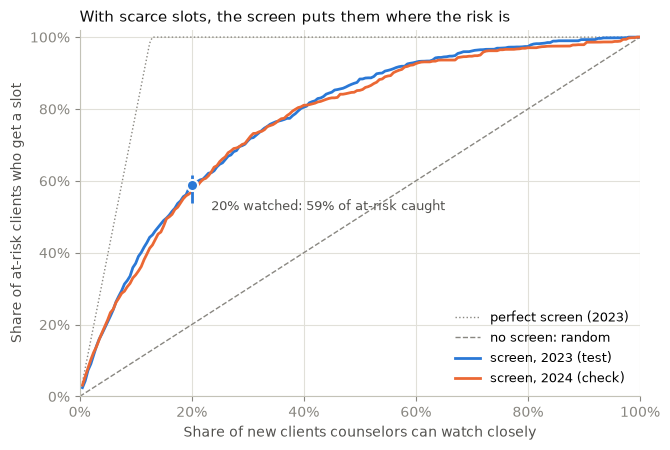

In [11]:
CAPS = np.array([0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50])

def caught_share(m, d, caps):
    """Share of at-risk clients (weighted) among the top `cap` of clients by predicted risk."""
    p = m.predict(design(d)).to_numpy()
    y, w = d.at_risk.to_numpy(), d.ANALWT2_C.to_numpy()
    order = np.argsort(-p)
    cum_w = np.cumsum(w[order]) / w.sum()
    out = []
    for cap in np.atleast_1d(caps):
        top = np.zeros(len(p), bool)
        top[order[cum_w <= cap]] = True
        out.append((w * y * top).sum() / (w * y).sum())
    return np.array(out)

cap_rng = np.random.default_rng(SEED + 3)
cap_reps = {"2023": [], "2024": []}
for b in range(B):
    tr, te, ch = half_sample(train, cap_rng), half_sample(test, cap_rng), half_sample(check, cap_rng)
    w = tr.ANALWT2_C / tr.ANALWT2_C.mean()
    m_b = sm.GLM(tr.at_risk, design(tr), family=sm.families.Binomial(), var_weights=w).fit()
    cap_reps["2023"].append(caught_share(m_b, te, CAPS))
    cap_reps["2024"].append(caught_share(m_b, ch, CAPS))

cap = pd.DataFrame(index=pd.Index(CAPS, name="capacity (share of new clients watched)"))
for yr, d in [("2023", test), ("2024", check)]:
    rate = wmean(d.at_risk, d.ANALWT2_C)
    arr = np.array(cap_reps[yr])
    cap[f"caught {yr}"] = caught_share(model, d, CAPS)
    cap[f"low {yr}"] = np.percentile(arr, 2.5, axis=0)
    cap[f"high {yr}"] = np.percentile(arr, 97.5, axis=0)
    cap[f"random {yr}"] = CAPS
    cap[f"at-risk on close per 100, screen {yr}"] = 100 * rate * cap[f"caught {yr}"]
    cap[f"at-risk on close per 100, random {yr}"] = 100 * rate * CAPS
display(cap.round(3))

# The capture curve: share of at-risk clients caught against the share of clients watched.
grid = np.linspace(0.005, 1, 200)
fig, ax = plt.subplots(figsize=(6.8, 4.6))
p23 = wmean(test.at_risk, test.ANALWT2_C)
ax.plot(grid, np.minimum(1, grid / p23), color="#898781", lw=1, ls=":", label="perfect screen (2023)")
ax.plot([0, 1], [0, 1], color="#898781", lw=1, ls="--", label="no screen: random")
for yr, d in [("2023", test), ("2024", check)]:
    ax.plot(grid, caught_share(model, d, grid), color=COLORS_YR[yr], lw=2,
            label=f"screen, {yr} ({'test' if yr == '2023' else 'check'})")
k = list(CAPS).index(0.20)
ax.errorbar([0.20], [cap["caught 2023"].iloc[k]], yerr=[[cap["caught 2023"].iloc[k] - cap["low 2023"].iloc[k]],
            [cap["high 2023"].iloc[k] - cap["caught 2023"].iloc[k]]], color=COLORS_YR["2023"], marker="o", ms=8,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5, lw=0, elinewidth=2)
ax.annotate(f"20% watched: {cap['caught 2023'].iloc[k]:.0%} of at-risk caught", (0.20, cap["caught 2023"].iloc[k]),
            xytext=(14, -18), textcoords="offset points", fontsize=9, color="#52514e")
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("Share of new clients counselors can watch closely", color="#52514e")
ax.set_ylabel("Share of at-risk clients who get a slot", color="#52514e")
ax.set_title("With scarce slots, the screen puts them where the risk is", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
for side in ("left", "bottom"): ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "capacity.png", dpi=150); plt.show()


**Reading.** With scarce slots, the screen puts them where the risk is.

- If counselors can watch 1 in 5 new clients closely, the screen gives a slot to 58.8% of at-risk clients on 2023 (95% interval 53.9% to 61.6%), against 20% at random. That is 7.5 at-risk clients on close monitoring per 100 new clients, against 2.5. The 2024 check gives 57.0% (52.8% to 60.6%).
- At 10% capacity the screen reaches 37% of at-risk clients against 10%, and at 50%, 88% against 50%.
- The risk that remains: at 20% capacity, 41% of at-risk clients still start on standard monitoring, 5.2 per 100 new clients.
- Value of being less wrong: a perfect screen would give every at-risk client a slot once 13% of clients can be watched. This one reaches 59% at 20%, so better predictors are worth up to 5.2 more at-risk clients on close monitoring per 100 new clients. Raising capacity from 20% to 30% adds 1.6 (7.5 to 9.0).

Under capacity, the answer does not depend on r. The r-based loss above answers a different question, whether to watch everyone if time were unlimited, and there the screen pays only when r ≤ 29.

## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.


In [12]:
# Key effects in real units: predicted risk for a few example new clients.
examples = pd.DataFrame([
    {"who": "30, low distress (K6 4), nothing else",           "age": "26-34", "KSSLR6MON": 4,  "UD5ILALANY": 0, "IRMHTRXMED": 0, "IRMHTPHVID": 0},
    {"who": "30, high distress (K6 16), nothing else",          "age": "26-34", "KSSLR6MON": 16, "UD5ILALANY": 0, "IRMHTRXMED": 0, "IRMHTPHVID": 0},
    {"who": "22, high distress, substance use disorder, on Rx", "age": "18-25", "KSSLR6MON": 16, "UD5ILALANY": 1, "IRMHTRXMED": 1, "IRMHTPHVID": 0},
    {"who": "70, low distress (K6 4), on Rx",                   "age": "65+",   "KSSLR6MON": 4,  "UD5ILALANY": 0, "IRMHTRXMED": 1, "IRMHTPHVID": 0},
])
examples["age"] = pd.Categorical(examples.age, categories=list(AGE.values()), ordered=True)
examples["predicted risk"] = model.predict(design(examples)).to_numpy()
for r_ in [10, 29]:
    examples[f"close at r={r_}?"] = np.where(examples["predicted risk"] > 1 / (1 + r_), "yes", "no")
display(examples.set_index("who")[["predicted risk", "close at r=10?", "close at r=29?"]].round(3))


,predicted risk,close at r=10?,close at r=29?
who,,,
"30, low distress (K6 4), nothing else",0.028,no,no
"30, high distress (K6 16), nothing else",0.209,yes,yes
"22, high distress, substance use disorder, on Rx",0.501,yes,yes
"70, low distress (K6 4), on Rx",0.018,no,no


**Key effects in plain language.** Distress is the strongest signal: each point on the K6 scale (0 to 24) multiplies the odds of serious thoughts of suicide by 1.20. A 30-year-old with low distress (K6 4) has a predicted risk of 2.8%. The same person with high distress (K6 16) is at 20.9%. A 22-year-old with high distress, a substance use disorder, and psychiatric medication is at 50%. A 70-year-old with low distress who takes medication is at 1.8%. A drug or alcohol use disorder multiplies the odds by 1.43, medication by 1.50, and phone or video treatment by 1.30. Adults 65 and over have about a quarter of the odds of 18–25-year-olds.

**Where not to trust the model.**

- When r is 50 or more: the screen is no better than starting everyone on close monitoring.
- Predicted risks above about 30%: they are too high, more so on 2024. No threshold in use is that high.
- For FirstHarbor's actual clients. They are invited by counselors, use an app, and are scored at intake, not over the past year. The survey cannot say whether the thoughts of suicide came before or after treatment began.
- After the definition of treatment changes again, as it did in 2022 and in June 2024.

**What was assumed.**

- The range of r, 2 to 500. It rests on Stanley et al. (2018), where the safety plan, not the number of calls, seemed to do the work, and on an assumed 30 to 60 minutes of counselor review.
- The outcome is serious thoughts of suicide, while the cost of a miss comes from suicidal behavior that was prevented.
- In the r-based loss, counselors can monitor every client closely. The capacity view drops that assumption, but its capacity levels (5% to 50%) are illustrations: FirstHarbor's counselors have not given theirs.
- About 2% of the outcome values were imputed by SAMHSA.

**With more time or data.**

- Ask counselors for r directly. The decision turns on it.
- Ask counselors what share of new clients they can watch closely in week 1. That sets the capacity, and the slots go to the highest predicted risk.
- Once FirstHarbor has clients, score the screen on their own intake answers and first weeks.
- Use the restricted NSDUH files, which carry the interview month, to separate the old and new 2024 wording.
- Look for better predictors before more rows: halving the data cost little.